# 1. Importuri


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from keras import layers



# 2. Incarcarea Datelor

In [3]:
data_dir = Path('date_raw')
csv_files = sorted(data_dir.glob('*.csv'))
dfs = []
for csv_path in csv_files:
    df_file = pd.read_csv(csv_path)
    df_file['source_file'] = csv_path.name
    split_idx = int(len(df_file) * 0.8)
    df_file['split'] = 'train'
    if split_idx < len(df_file):
        df_file.loc[df_file.index >= split_idx, 'split'] = 'test'
    dfs.append(df_file)

df = pd.concat(dfs, ignore_index=True)
print(f'Loaded {len(csv_files)} files from {data_dir}')
print(df['split'].value_counts())
print(df.head())
print(df.label.value_counts())

Loaded 25 files from date_raw
split
train    430643
test     107684
Name: count, dtype: int64
     ax    ay     az    gx    gy    gz   temp  label           source_file  \
0  0.08  1.12 -10.57 -0.08 -0.02 -0.02  24.09      2  dezechilibru_160.csv   
1  0.11  1.30 -10.88 -0.10  0.05 -0.01  24.10      2  dezechilibru_160.csv   
2  0.42  1.14 -10.63 -0.05  0.02 -0.01  24.09      2  dezechilibru_160.csv   
3  0.23  0.94 -10.50 -0.10  0.05 -0.01  24.09      2  dezechilibru_160.csv   
4  0.12  1.15 -10.74 -0.09  0.00 -0.02  24.10      2  dezechilibru_160.csv   

   split  
0  train  
1  train  
2  train  
3  train  
4  train  
label
2    129216
1    129216
3    129215
4    129144
0     21536
Name: count, dtype: int64


# 3. Pregatirea Datelor

In [22]:
drop_columns = ['label', 'split', 'source_file', 'pwm_speed']
feature_columns = [col for col in df.columns if col not in drop_columns]
label_column = 'label'
train_df = df[df['split'] == 'train'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)
X_train_raw = train_df[feature_columns].values
y_train_raw = train_df[label_column].values
X_test_raw = test_df[feature_columns].values
y_test_raw = test_df[label_column].values
num_features = len(feature_columns)
num_classes = df[label_column].nunique()
print('Features used:', feature_columns)
print('Train samples:', X_train_raw.shape, 'Test samples:', X_test_raw.shape)
window_size = 128
step_size = 64

Features used: ['ax', 'ay', 'az', 'gx', 'gy', 'gz', 'temp']
Train samples: (430643, 7) Test samples: (107684, 7)


In [23]:
# Optional high-pass filtering to suppress quasi-static gravity components on accelerometer axes
use_high_pass_filter = True
high_pass_window = 256  # samples (~2 s at 128 Hz)
accelerometer_columns = ['ax', 'ay', 'az']  # adjust if your column names differ
acc_feature_indices = [feature_columns.index(col) for col in accelerometer_columns if col in feature_columns]
def apply_high_pass_filter(X, column_indices, window_samples):
    if not column_indices or window_samples <= 1:
        return X
    rolling_mean = (
        pd.DataFrame(X[:, column_indices])
        .rolling(window_samples, min_periods=1, center=True)
        .mean()
        .values
    )
    X_filtered = X.copy()
    X_filtered[:, column_indices] = X_filtered[:, column_indices] - rolling_mean
    return X_filtered
if use_high_pass_filter and acc_feature_indices:
    X_train_pre = apply_high_pass_filter(X_train_raw, acc_feature_indices, high_pass_window)
    X_test_pre = apply_high_pass_filter(X_test_raw, acc_feature_indices, high_pass_window)
    print(f'Applied high-pass filter (window={high_pass_window}) to accelerometer axes {accelerometer_columns}.')
else:
    X_train_pre = X_train_raw
    X_test_pre = X_test_raw
    if use_high_pass_filter and not acc_feature_indices:
        print('Warning: accelerometer columns not found; skipping high-pass filter.')

Applied high-pass filter (window=256) to accelerometer axes ['ax', 'ay', 'az'].


# 4. Normalizarea Datelor

In [24]:
scaler = StandardScaler()
X_train_seq = scaler.fit_transform(X_train_pre).astype(np.float32)
X_test_seq = scaler.transform(X_test_pre).astype(np.float32)
print('Scaler fitted on train samples only (post-filter).')
means = scaler.mean_
scales = scaler.scale_
np.save('scaler_mean.npy', means)
np.save('scaler_scale.npy', scales)
print("Means:", means)
print("Scales:", scales)

Scaler fitted on train samples only (post-filter).
Means: [-5.65360547e-07  1.74972845e-07 -9.71855915e-08 -8.21027394e-02
  2.17949671e-02 -1.04382981e-02  2.41762550e+01]
Scales: [0.28544454 0.20158326 0.25337512 0.02341237 0.03009384 0.00575981
 0.66037677]


# 5. Window Slicing

In [25]:
def window_slicing(X, y, window_size, step_size):
    X_windows = []
    y_windows = []
    for start in range(0, X.shape[0] - window_size + 1, step_size):
        end = start + window_size
        X_windows.append(X[start:end])
        window_labels = y[start:end].astype(int)
        majority_label = np.bincount(window_labels).argmax()
        y_windows.append(majority_label)
    return np.array(X_windows), np.array(y_windows)

X_train_windows, y_train_windows = window_slicing(X_train_seq, y_train_raw, window_size, step_size)
X_val_windows, y_val_windows = window_slicing(X_test_seq, y_test_raw, window_size, step_size)
print('Train windows:', X_train_windows.shape, 'Validation windows:', X_val_windows.shape)

Train windows: (6727, 128, 7) Validation windows: (1681, 128, 7)


# 6. Split + Shuffle

In [26]:
X_train, X_val = X_train_windows, X_val_windows
y_train, y_val = y_train_windows, y_val_windows
print('Using deterministic train/test splits per file (no random shuffling).')

Using deterministic train/test splits per file (no random shuffling).


# 7. CNN 1D

In [28]:
model = keras.Sequential([
    layers.Input(shape=(window_size, num_features)),
    layers.Conv1D(64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')

])
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
checkpoint_path = 'checkpoints/best_model.keras'
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min'
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        mode='min',
        restore_best_weights=True
    )
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)
val_loss, val_accuracy = model.evaluate(X_val, y_val)
print(f'Validation Loss: {val_loss}, Validation Accuracy: {val_accuracy}')
print(f"Best checkpoint saved to {checkpoint_path}")

Epoch 1/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7859 - loss: 0.6952 - val_accuracy: 0.9393 - val_loss: 0.2412
Epoch 2/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7859 - loss: 0.6952 - val_accuracy: 0.9393 - val_loss: 0.2412
Epoch 2/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9443 - loss: 0.1791 - val_accuracy: 0.9441 - val_loss: 0.1498
Epoch 3/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9443 - loss: 0.1791 - val_accuracy: 0.9441 - val_loss: 0.1498
Epoch 3/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9582 - loss: 0.1138 - val_accuracy: 0.9792 - val_loss: 0.0813
Epoch 4/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9582 - loss: 0.1138 - val_accuracy: 0.9792 - val_loss: 0.0813
Epoch 4/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9759 - loss: 0.0740 - val_accuracy: 0.9655 - val_loss: 0.0656
Epoch 5/100
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9759 - loss: 0.0740 - val_accu

# 8. Evaluare detaliata

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        66
           1     0.9951    1.0000    0.9975       404
           2     1.0000    1.0000    1.0000       403
           3     0.9975    0.9950    0.9963       404
           4     1.0000    0.9975    0.9988       404

    accuracy                         0.9982      1681
   macro avg     0.9985    0.9985    0.9985      1681
weighted avg     0.9982    0.9982    0.9982      1681

Confusion matrix (counts):
     0    1    2    3    4
0  66    0    0    0    0
1   0  404    0    0    0
2   0    0  403    0    0
3   0    2    0  402    0
4   0    0    0    1  403
Row-normalized confusion matrix (per true label):
      0      1    2       3       4
0  1.0  0.000  0.0  0.0000  0.0000
1  0.0  1.000  0.0  0.0000  0.0000
2  0.0  0.000  1.0  0.0000  0.0000
3  0.0  0.005  0.0  0.9950  0.0000
4  0.0  0.000  0.0  0.0

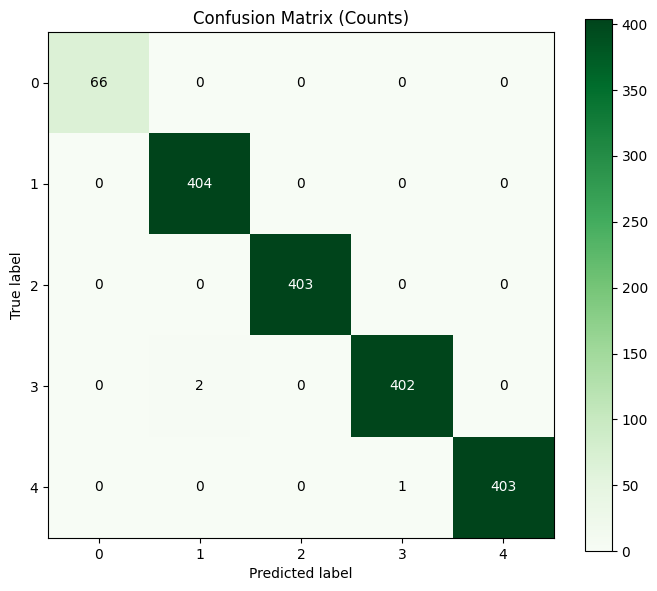

In [29]:
label_values = sorted(df[label_column].unique())
y_val_pred = np.argmax(model.predict(X_val), axis=1)
print(classification_report(y_val, y_val_pred, digits=4))
cm = confusion_matrix(y_val, y_val_pred)
cm_df = pd.DataFrame(cm, index=label_values, columns=label_values)
print("Confusion matrix (counts):\n", cm_df)
cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), where=cm.sum(axis=1, keepdims=True)!=0)
cm_norm_df = pd.DataFrame(np.round(cm_norm, 4), index=label_values, columns=label_values)
print("Row-normalized confusion matrix (per true label):\n", cm_norm_df)
misclass_pairs = []
for i, true_label in enumerate(label_values):
    for j, pred_label in enumerate(label_values):
        if i != j and cm[i, j] > 0:
            misclass_pairs.append((cm[i, j], true_label, pred_label))
if misclass_pairs:
    misclass_pairs.sort(reverse=True)
    print("Top misclassifications (count, true -> predicted):")
    for count, true_label, pred_label in misclass_pairs[:10]:
        pct = cm_norm[label_values.index(true_label), label_values.index(pred_label)] * 100
        print(f"  {count} samples ({pct:.2f}%) : {true_label} → {pred_label}")
else:
    print("Perfect confusion matrix (no off-diagonal errors).")
plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Greens)
plt.title('Confusion Matrix (Counts)')
plt.colorbar()
tick_marks = np.arange(len(label_values))
plt.xticks(tick_marks, label_values)
plt.yticks(tick_marks, label_values)
for i in range(len(label_values)):
    for j in range(len(label_values)):
        value = cm[i, j]
        plt.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else 'black')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()

# 9. Salvarea modelului si conversia


In [30]:
model.save('cnn1d_model.h5')
np.save('scaler_mean.npy', scaler.mean_)
np.save('scaler_scale.npy', scaler.scale_)
converted_model = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converted_model.convert()
with open('cnn1d_model.tflite', 'wb') as f:
    f.write(tflite_model)

INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpekqfzn7y\assets


INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpekqfzn7y\assets


Saved artifact at 'C:\Users\Cristi\AppData\Local\Temp\tmpekqfzn7y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 7), dtype=tf.float32, name='keras_tensor_33')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2177909363664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909365392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909366544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364624: TensorSpec(shape=(), dtype=tf.resource, name=None)


# 10. Conversie TFLite cu cuantizare int8

In [31]:
def representative_dataset():
    for window in X_train[:1000]:
        yield [np.expand_dims(window, axis=0).astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_quant_model = converter.convert()
with open('cnn1d_model_int8.tflite', 'wb') as f:
    f.write(tflite_quant_model)
print('Saved quantized model to cnn1d_model_int8.tflite')

INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpf1j0u8qo\assets


INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpf1j0u8qo\assets


Saved artifact at 'C:\Users\Cristi\AppData\Local\Temp\tmpf1j0u8qo'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 7), dtype=tf.float32, name='keras_tensor_33')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2177909363664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909365392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909366544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177909364624: TensorSpec(shape=(), dtype=tf.resource, name=None)


c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved quantized model to cnn1d_model_int8.tflite


# 11. Salvarea fisierelor in forma values pentru mean si scale

In [32]:
mean = np.load("scaler_mean.npy")
scale = np.load("scaler_scale.npy")
print("float mean[] = {", ", ".join(f"{m:.8f}f" for m in mean), "};")
print("float scale[] = {", ", ".join(f"{s:.8f}f" for s in scale), "};")

float mean[] = { -0.00000057f, 0.00000017f, -0.00000010f, -0.08210274f, 0.02179497f, -0.01043830f, 24.17625500f };
float scale[] = { 0.28544454f, 0.20158326f, 0.25337512f, 0.02341237f, 0.03009384f, 0.00575981f, 0.66037677f };


# 12. scrierea modelului in bytes


In [33]:
import os

# Alege modelul pe care vrei sa il folosesti (cel simplu sau cel cuantificat int8)
# Recomandarea mea: incepe cu cel simplu, daca e prea mare treci la cel int8
input_model_path = 'cnn1d_model.tflite' 
output_header_path = 'model_data.h'

def convert_to_c_array(input_path, output_path):
    with open(input_path, 'rb') as f:
        data = f.read()

    # Cream continutul fisierului C
    c_content = []
    c_content.append('#ifndef MODEL_DATA_H')
    c_content.append('#define MODEL_DATA_H')
    c_content.append('')
    c_content.append('#include <stdint.h>')
    c_content.append('')
    # Adaugam lungimea
    c_content.append(f'const unsigned int model_data_len = {len(data)};')
    c_content.append('')
    # Adaugam array-ul cu aliniere (CRUCIAL pentru TensorFlow Lite Micro)
    # Folosim 'const' pentru a-l tine in Flash, nu in RAM
    c_content.append('const unsigned char model_data[] __attribute__((aligned(4))) = {')
    
    # Convertim bytes in hex strings
    hex_data = [f'0x{byte:02x}' for byte in data]
    
    # Le formatam frumos, cate 12 pe linie ca sa nu crape editorul
    for i in range(0, len(hex_data), 12):
        line = ', '.join(hex_data[i:i+12])
        if i + 12 < len(hex_data):
            line += ','
        c_content.append('  ' + line)
        
    c_content.append('};')
    c_content.append('')
    c_content.append('#endif // MODEL_DATA_H')

    # Scriem fisierul
    with open(output_path, 'w') as f:
        f.write('\n'.join(c_content))
    
    print(f"Succes! Fisierul '{output_path}' a fost generat corect.")
    print(f"Marime model: {len(data)} bytes")

# Rularea conversiei
convert_to_c_array(input_model_path, output_header_path)

Succes! Fisierul 'model_data.h' a fost generat corect.
Marime model: 27416 bytes
